# Predicción temprana del rendimiento académico — Entrega 2
**Aprendizaje Automático · UFV · María Carlota Abad y Adriana Soria**

Notebook del primer avance: análisis exploratorio (EDA), preparación de los datos y primeros modelos.

Datos: *Student Performance* (Cortez, 2008), UCI Machine Learning Repository, licencia CC BY 4.0.
Los ficheros `student-por.csv` y `student-mat.csv` deben estar en la misma carpeta que este notebook.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, recall_score, precision_score, confusion_matrix

SEMILLA = 42                       # para que los resultados salgan siempre iguales
os.makedirs("figuras", exist_ok=True)

## 1. Cargar los datos

In [2]:
por = pd.read_csv("student-por.csv", sep=";")   # Lengua portuguesa (tabla principal)
mat = pd.read_csv("student-mat.csv", sep=";")   # Matemáticas (para comparar más adelante)

print("Portugués:", por.shape, "| Matemáticas:", mat.shape)
print("Valores que faltan en Portugués:", por.isna().sum().sum())
por.head()

Portugués: (649, 33) | Matemáticas: (395, 33)
Valores que faltan en Portugués: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## 2. Análisis exploratorio (EDA)
### 2.1 ¿Cuántos aprueban?

In [3]:
por["aprobado"] = (por["G3"] >= 10).astype(int)   # 1 = aprueba, 0 = suspende
mat["aprobado"] = (mat["G3"] >= 10).astype(int)

print("Portugués  -> % aprobados:", round(por["aprobado"].mean() * 100, 1))
print("Matemáticas -> % aprobados:", round(mat["aprobado"].mean() * 100, 1))
print("Alumnos con nota final 0 (Portugués):", (por["G3"] == 0).sum())
print(por["G3"].describe().round(2))

Portugués  -> % aprobados: 84.6
Matemáticas -> % aprobados: 67.1
Alumnos con nota final 0 (Portugués): 15
count    649.00
mean      11.91
std        3.23
min        0.00
25%       10.00
50%       12.00
75%       14.00
max       19.00
Name: G3, dtype: float64


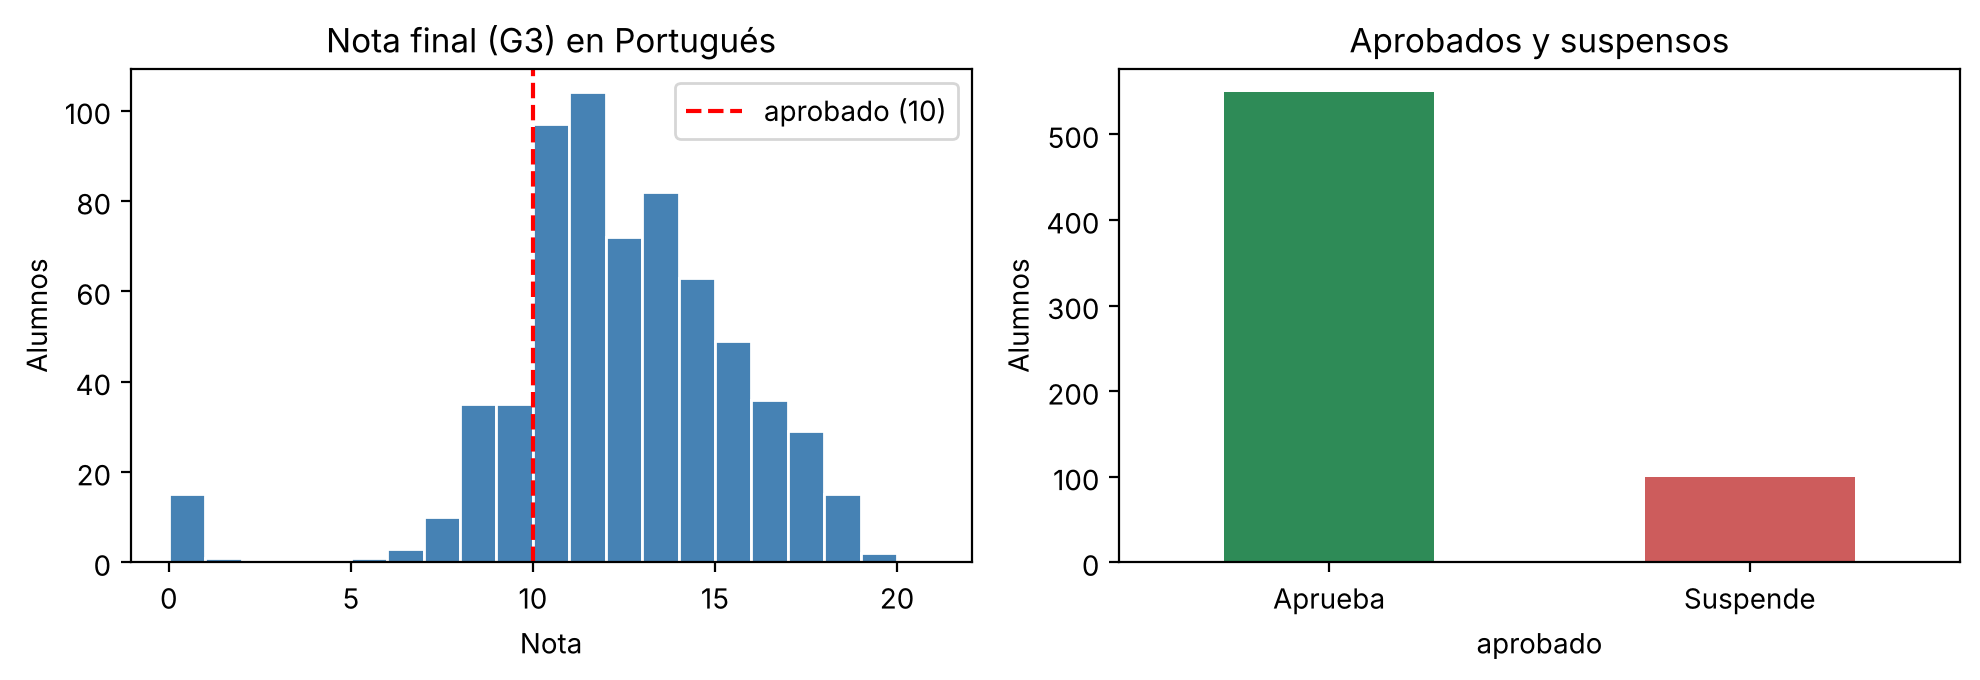

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(por["G3"], bins=range(0, 22), color="steelblue", edgecolor="white")
ax[0].axvline(10, color="red", linestyle="--", label="aprobado (10)")
ax[0].set_title("Nota final (G3) en Portugués"); ax[0].set_xlabel("Nota"); ax[0].set_ylabel("Alumnos")
ax[0].legend()
por["aprobado"].map({1: "Aprueba", 0: "Suspende"}).value_counts().plot.bar(ax=ax[1], color=["seagreen", "indianred"])
ax[1].set_title("Aprobados y suspensos"); ax[1].set_ylabel("Alumnos"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("figuras/fig1_notas.png", dpi=150); plt.show()

### 2.2 ¿Qué datos se relacionan con suspender?
Calculamos el **% de suspensos** en cada grupo de alumnos.

In [5]:
def pct_suspensos(columna):
    return (100 * (1 - por.groupby(columna)["aprobado"].mean())).round(1)

for col in ["failures", "studytime", "higher", "school", "sex", "Medu", "internet", "Dalc"]:
    print(f"\n% de suspensos según {col}:")
    print(pct_suspensos(col).to_string())


% de suspensos según failures:
failures
0     9.3
1    45.7
2    50.0
3    64.3

% de suspensos según studytime:
studytime
1    23.6
2    13.4
3     7.2
4     5.7

% de suspensos según higher:
higher
no     47.8
yes    11.6

% de suspensos según school:
school
GP     7.6
MS    30.1

% de suspensos según sex:
sex
F    13.1
M    18.8

% de suspensos según Medu:
Medu
0     0.0
1    25.9
2    14.5
3    15.8
4     8.0

% de suspensos según internet:
internet
no     21.2
yes    13.7

% de suspensos según Dalc:
Dalc
1    12.9
2    19.8
3    16.3
4    29.4
5    35.3


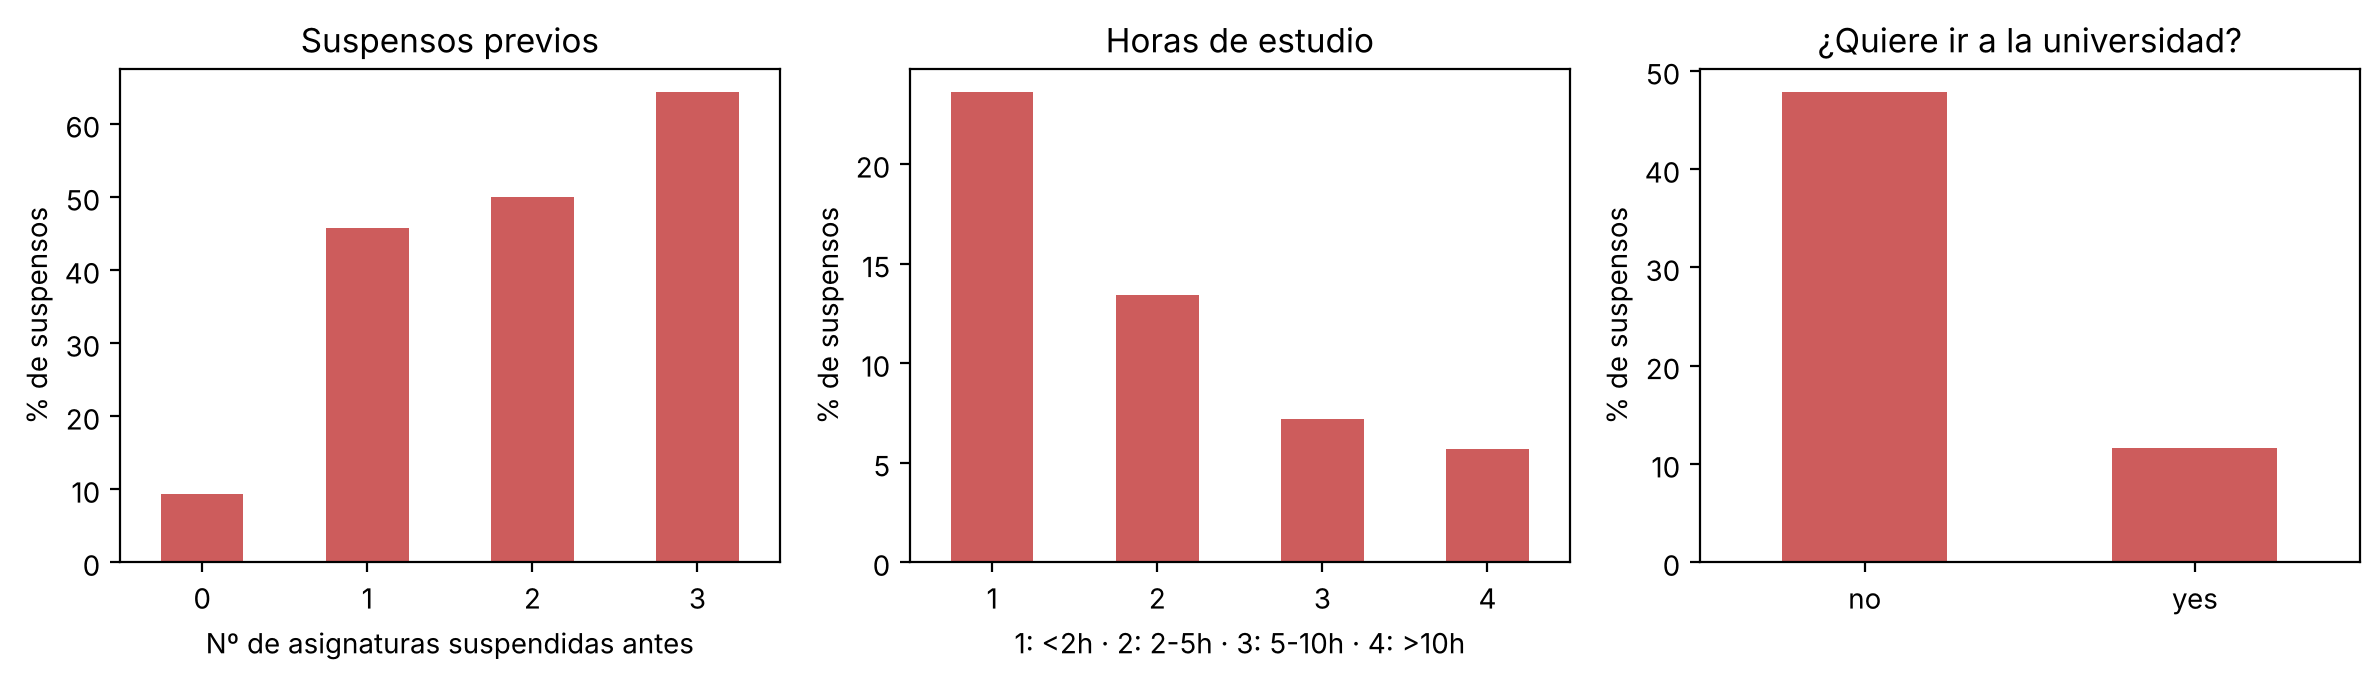

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
pct_suspensos("failures").plot.bar(ax=ax[0], color="indianred")
ax[0].set_title("Suspensos previos"); ax[0].set_xlabel("Nº de asignaturas suspendidas antes")
pct_suspensos("studytime").plot.bar(ax=ax[1], color="indianred")
ax[1].set_title("Horas de estudio"); ax[1].set_xlabel("1: <2h · 2: 2-5h · 3: 5-10h · 4: >10h")
pct_suspensos("higher").plot.bar(ax=ax[2], color="indianred")
ax[2].set_title("¿Quiere ir a la universidad?"); ax[2].set_xlabel("")
for a in ax:
    a.set_ylabel("% de suspensos"); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("figuras/fig2_factores.png", dpi=150); plt.show()

### 2.3 Correlación de las variables numéricas con la nota final

failures     -0.39
Dalc         -0.20
Walc         -0.18
traveltime   -0.13
freetime     -0.12
age          -0.11
health       -0.10
absences     -0.09
goout        -0.09
famrel        0.06
Fedu          0.21
Medu          0.24
studytime     0.25
G1            0.83
G2            0.92


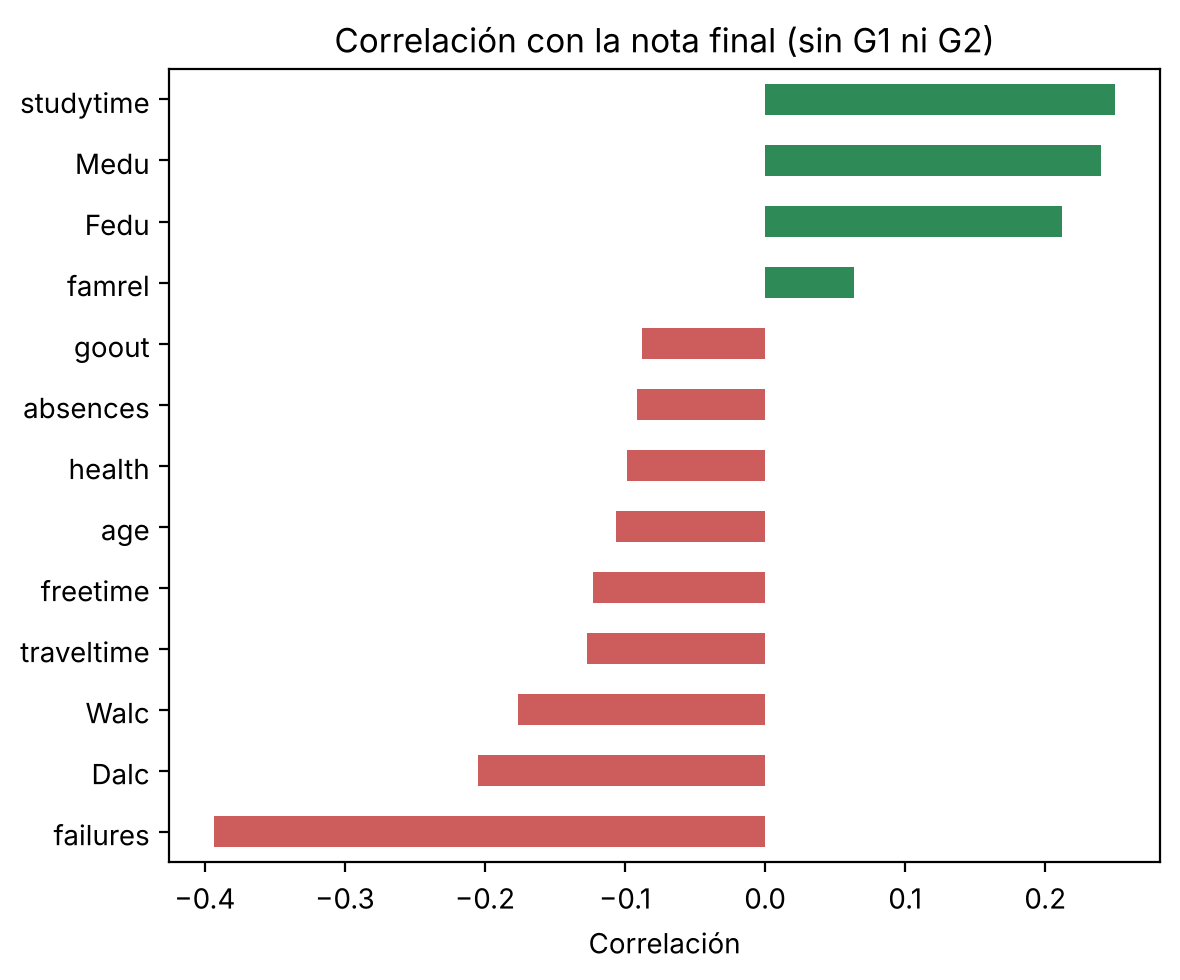

In [7]:
numericas = por.select_dtypes("number").drop(columns=["aprobado"])
corr = numericas.corr()["G3"].drop("G3").sort_values()
print(corr.round(2).to_string())

corr.drop(["G1", "G2"]).plot.barh(figsize=(6, 5), color=["indianred" if c < 0 else "seagreen" for c in corr.drop(["G1", "G2"])])
plt.title("Correlación con la nota final (sin G1 ni G2)"); plt.xlabel("Correlación")
plt.tight_layout(); plt.savefig("figuras/fig3_correlaciones.png", dpi=150); plt.show()

## 3. Preparación de los datos (preprocesado)
1. Convertimos los datos de texto en números (sí/no → 1/0; las categorías con más opciones, en varias columnas de 0 y 1).
2. Creamos tres variables nuevas sencillas (ingeniería de características).
3. Preparamos dos escenarios: **A** sin ninguna nota y **B** añadiendo la nota del primer trimestre (G1).
4. Separamos 80 % para entrenar y 20 % para probar, manteniendo la misma proporción de suspensos en las dos partes.

In [8]:
def preparar(df):
    df = df.copy()
    # Variables nuevas
    df["alcohol_total"] = df["Dalc"] + df["Walc"]          # consumo entre semana + fin de semana
    df["estudios_padres"] = df["Medu"] + df["Fedu"]        # estudios de la madre + del padre
    df["ha_suspendido"] = (df["failures"] > 0).astype(int)  # ¿ha suspendido alguna vez?
    # Texto -> números
    si_no = [c for c in df.columns if set(df[c].unique()) <= {"yes", "no"}]
    df[si_no] = (df[si_no] == "yes").astype(int)
    df = pd.get_dummies(df, drop_first=True, dtype=int)
    return df

datos = preparar(por)
y = datos["aprobado"]
X_B = datos.drop(columns=["G2", "G3", "aprobado"])   # escenario B: con la nota del 1er trimestre
X_A = X_B.drop(columns=["G1"])                        # escenario A: sin ninguna nota
print("Columnas escenario A:", X_A.shape[1], "| escenario B:", X_B.shape[1])

Columnas escenario A: 42 | escenario B: 43


In [9]:
XA_train, XA_test, y_train, y_test = train_test_split(X_A, y, test_size=0.2, stratify=y, random_state=SEMILLA)
XB_train, XB_test = X_B.loc[XA_train.index], X_B.loc[XA_test.index]   # mismos alumnos en los dos escenarios

print("Entrenamiento:", len(y_train), "alumnos,", (y_train == 0).sum(), "suspensos")
print("Prueba:       ", len(y_test), "alumnos,", (y_test == 0).sum(), "suspensos")

Entrenamiento: 519 alumnos, 80 suspensos
Prueba:        130 alumnos, 20 suspensos


## 4. Primeros modelos
Medimos tres cosas sobre el 20 % de prueba:
- **Acierto**: % de alumnos bien clasificados.
- **Detección de suspensos** (*recall*): de los que suspenden, ¿cuántos detecta el modelo? Objetivo O1: al menos 70 %.
- **Precisión de los avisos**: de los alumnos que el modelo marca como «en riesgo», ¿cuántos suspenden de verdad?

In [10]:
def evaluar(nombre, modelo, X_tr, X_te, escalar=False):
    if escalar:   # la regresión logística funciona mejor con los datos en la misma escala
        sc = StandardScaler().fit(X_tr)
        X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
    modelo.fit(X_tr, y_train)
    pred = modelo.predict(X_te)
    return {"Modelo": nombre,
            "Acierto (%)": round(100 * accuracy_score(y_test, pred), 1),
            "Detecta suspensos (%)": round(100 * recall_score(y_test, pred, pos_label=0), 1),
            "Precisión avisos (%)": round(100 * precision_score(y_test, pred, pos_label=0, zero_division=0), 1)}

resultados = []
for esc, Xtr, Xte in [("A (sin notas)", XA_train, XA_test), ("B (con G1)", XB_train, XB_test)]:
    modelos = [
        ("Siempre 'aprobado'", DummyClassifier(strategy="most_frequent"), False),
        ("Regresión logística", LogisticRegression(max_iter=1000), True),
        ("Reg. logística equilibrada", LogisticRegression(max_iter=1000, class_weight="balanced"), True),
        ("Árbol (profundidad 4)", DecisionTreeClassifier(max_depth=4, random_state=SEMILLA), False),
        ("Árbol equilibrado (prof. 4)", DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEMILLA), False),
    ]
    for nombre, modelo, escalar in modelos:
        r = evaluar(nombre, modelo, Xtr, Xte, escalar)
        r["Escenario"] = esc
        resultados.append(r)

tabla = pd.DataFrame(resultados)[["Escenario", "Modelo", "Acierto (%)", "Detecta suspensos (%)", "Precisión avisos (%)"]]
tabla

,Escenario,Modelo,Acierto (%),Detecta suspensos (%),Precisión avisos (%)
0,A (sin notas),Siempre 'aprobado',84.6,0.0,0.0
1,A (sin notas),Regresión logística,79.2,35.0,33.3
2,A (sin notas),Reg. logística equilibrada,64.6,45.0,20.5
3,A (sin notas),Árbol (profundidad 4),76.9,20.0,22.2
4,A (sin notas),Árbol equilibrado (prof. 4),70.8,45.0,25.0
5,B (con G1),Siempre 'aprobado',84.6,0.0,0.0
6,B (con G1),Regresión logística,84.6,50.0,50.0
7,B (con G1),Reg. logística equilibrada,79.2,70.0,40.0
8,B (con G1),Árbol (profundidad 4),86.9,70.0,56.0
9,B (con G1),Árbol equilibrado (prof. 4),80.8,45.0,39.1


### 4.1 Matriz de confusión del mejor modelo sin notas

In [11]:
sc = StandardScaler().fit(XA_train)
logA = LogisticRegression(max_iter=1000, class_weight="balanced").fit(sc.transform(XA_train), y_train)
cm = confusion_matrix(y_test, logA.predict(sc.transform(XA_test)), labels=[0, 1])
print(pd.DataFrame(cm, index=["Real: suspende", "Real: aprueba"], columns=["Predice: suspende", "Predice: aprueba"]))

                Predice: suspende  Predice: aprueba
Real: suspende                  9                11
Real: aprueba                  35                75


### 4.2 ¿Qué datos usa más el modelo? (primer vistazo)

In [12]:
coef = pd.Series(logA.coef_[0], index=XA_train.columns).sort_values()
print("Datos que más empujan hacia SUSPENDER:"); print(coef.head(6).round(2).to_string())
print("\nDatos que más empujan hacia APROBAR:");  print(coef.tail(6).round(2).to_string())

arbol = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=SEMILLA).fit(XA_train, y_train)
imp = pd.Series(arbol.feature_importances_, index=XA_train.columns).sort_values(ascending=False)
print("\nImportancia en el árbol (top 6):"); print(imp.head(6).round(3).to_string())

Datos que más empujan hacia SUSPENDER:
school_MS         -1.18
guardian_mother   -0.80
Fjob_services     -0.72
failures          -0.49
absences          -0.45
ha_suspendido     -0.41

Datos que más empujan hacia APROBAR:
address_U       0.26
famsize_LE3     0.28
Mjob_health     0.33
age             0.39
Mjob_teacher    0.59
higher          0.63

Importancia en el árbol (top 6):
ha_suspendido      0.374
school_MS          0.200
guardian_mother    0.104
absences           0.080
Walc               0.046
higher             0.040


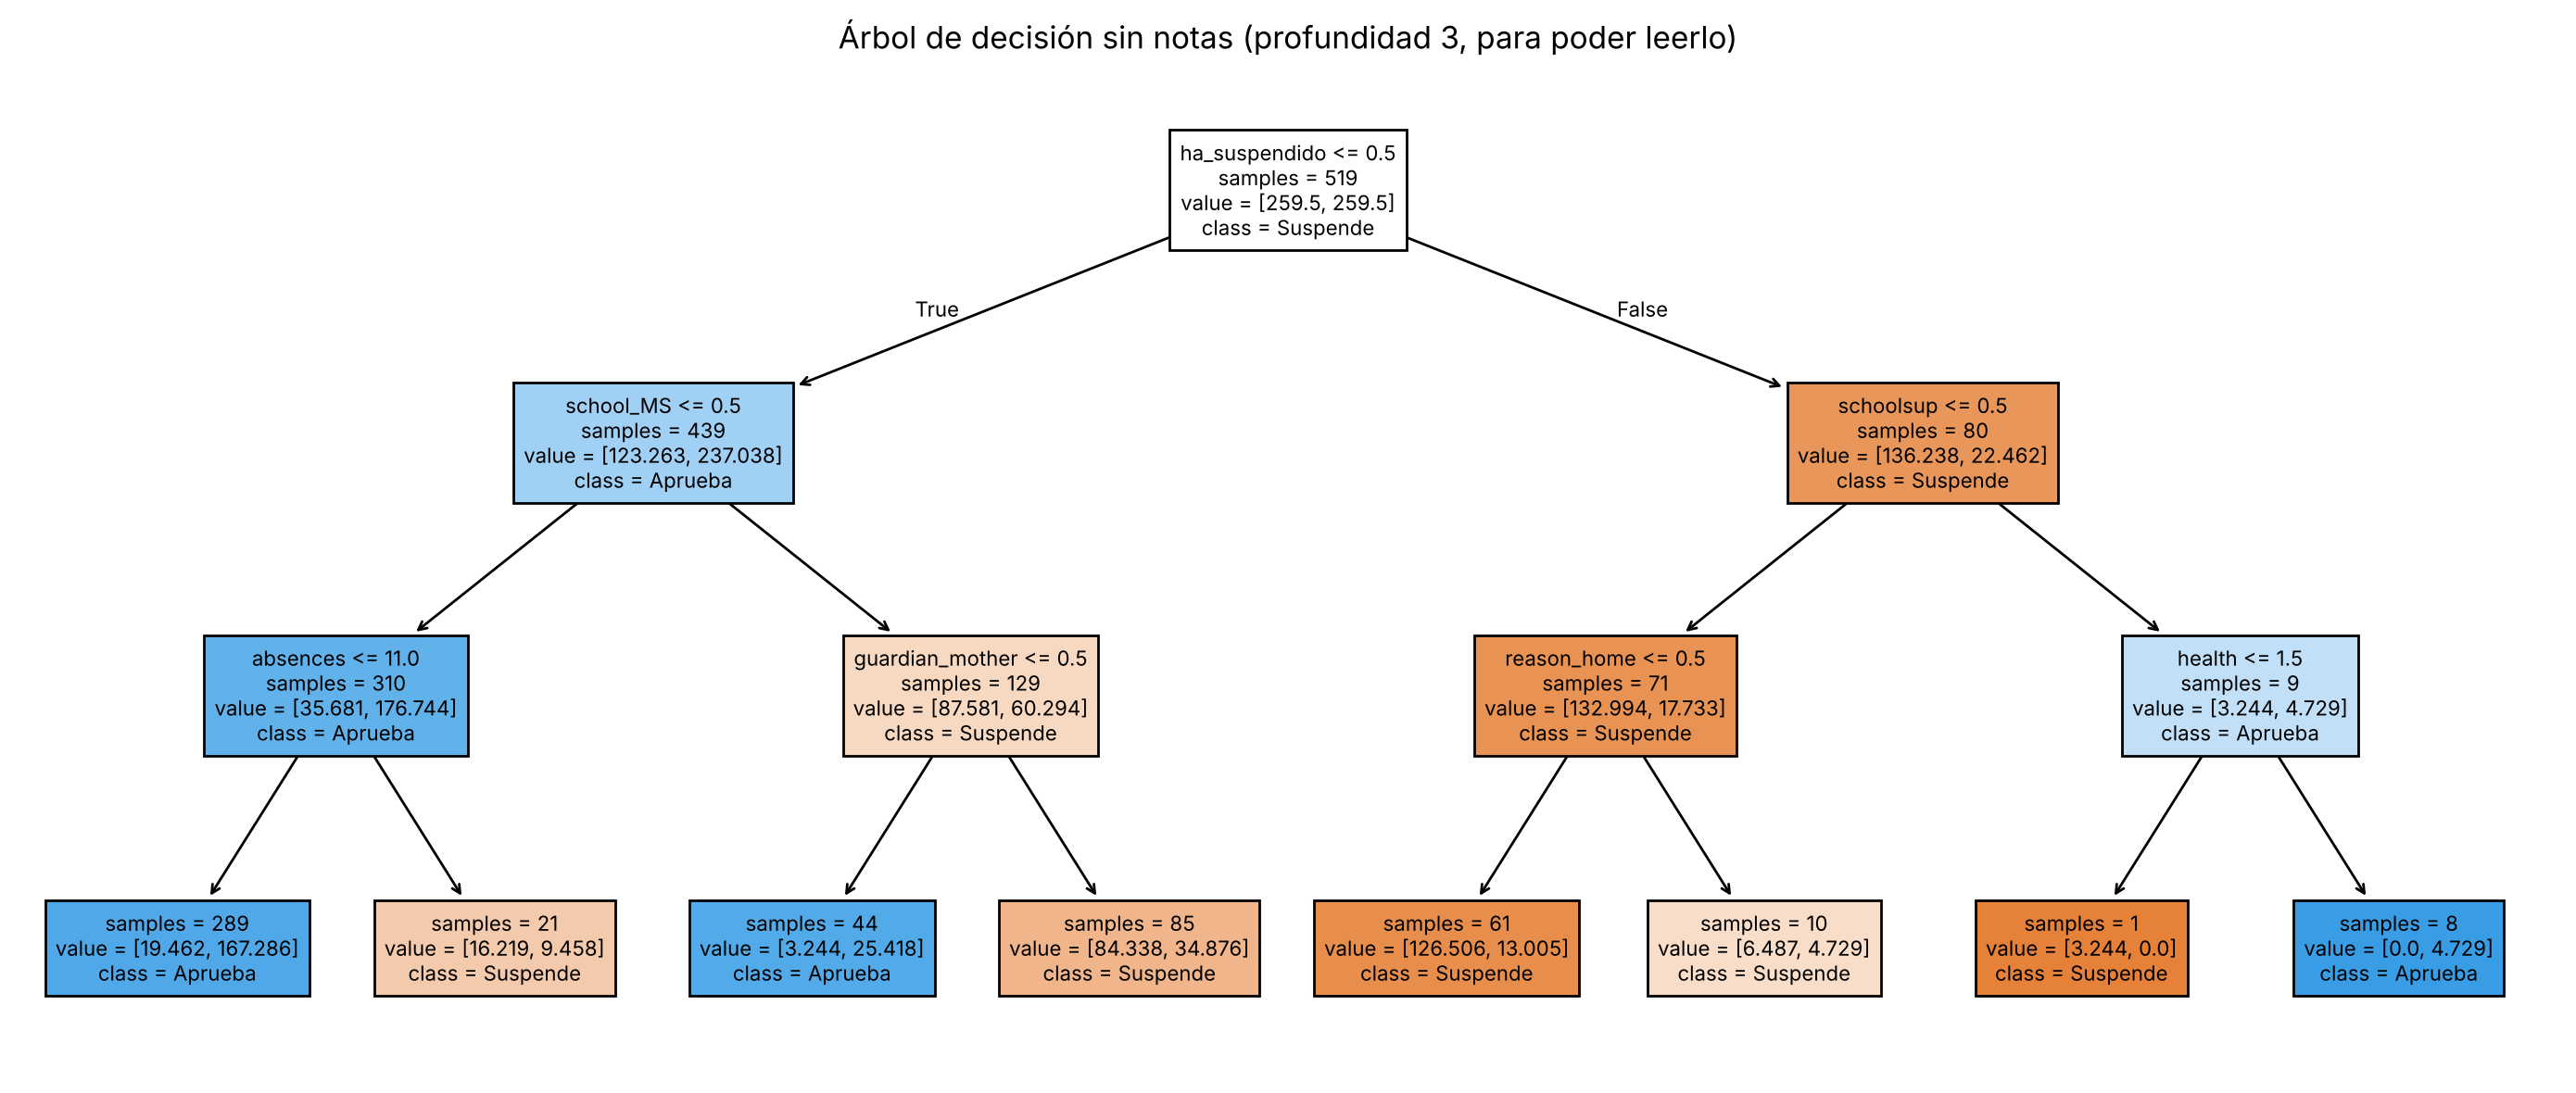

In [13]:
plt.figure(figsize=(14, 6))
arbol3 = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMILLA).fit(XA_train, y_train)
plot_tree(arbol3, feature_names=XA_train.columns, class_names=["Suspende", "Aprueba"], filled=True, fontsize=8, impurity=False)
plt.title("Árbol de decisión sin notas (profundidad 3, para poder leerlo)")
plt.tight_layout(); plt.savefig("figuras/fig4_arbol.png", dpi=150); plt.show()

## 5. Siguientes pasos (ver documento)
Bosque aleatorio, validación cruzada y ajuste de hiperparámetros, regresión de la nota exacta, revisión de justicia por sexo, repetición con Matemáticas.